<a href="https://colab.research.google.com/github/mullinskatie7-source/katherine-mullins.github.io/blob/main/Katherine_Mullins_Housing_Price_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 1: Markdown
# Housing Price Dataset

**Engineer:** Katherine Mullins

**Completion Date:** 11/17/2026

**Class:** EGN3443

**Assignment #:** 13

**Tool Used:** Colab / Python

## Problem Description

The objective of this analysis is to determine whether multiple housing characteristics can be combined to predict home price more accurately than living square footage alone.

The simple regression model from Assignment 11 used:

$$
\widehat{Price}
=
-43{,}579.34
+
280.6231(\text{sqft\_living})
$$

The model produced:

$$
R^2 = 0.4929
$$

which means approximately 49.3% of the variation in home price was explained by living square footage alone.

For the multiple-regression analysis, several additional predictors were evaluated, including:


* living square footage

* construction grade

* bathrooms

* nearby-home living area

* view

* waterfront status

* latitude

* bedrooms

The general multiple-regression model is:

$$
\hat{y}
=
b_0
+b_1x_1
+b_2x_2
+\cdots
+b_kx_k
$$

where each independent variable represents a housing characteristic that may contribute to property value.

The primary question is whether adding these variables significantly improves the ability to predict home price compared with the original simple regression model.

## Methodology

The analysis from Assignment 11 was expanded from a simple linear regression model to a multiple linear regression model. The original analysis used living square footage (sqft_living) as the only independent variable for predicting home price. Additional housing characteristics were evaluated to determine whether they improved the predictive ability of the model.

The analysis followed the Gold Standard Approach provided in the assignment.

Scatter plots and other appropriate visualizations were used to examine the relationship between home price and potential predictor variables. This allowed the general direction and form of each relationship to be observed before fitting the regression model.

Housing.csv extracted successfully!
Dataset shape:
(21613, 21)

First five rows:
           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7229300521  20141013T000000  231300.0         2       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8 

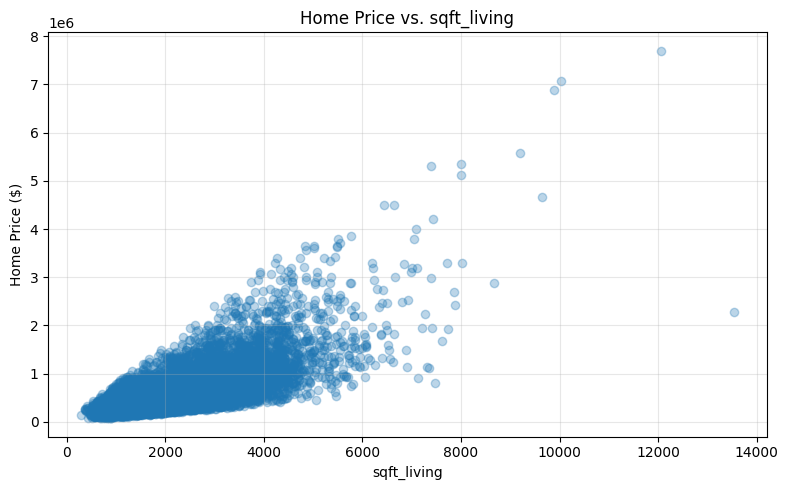

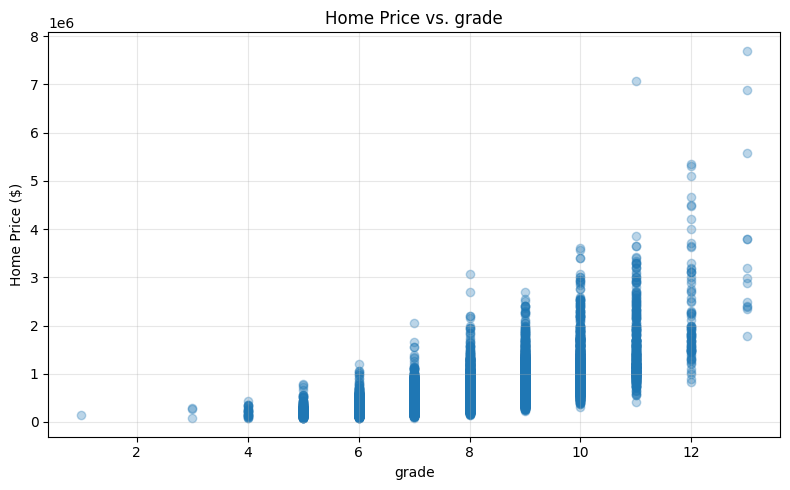

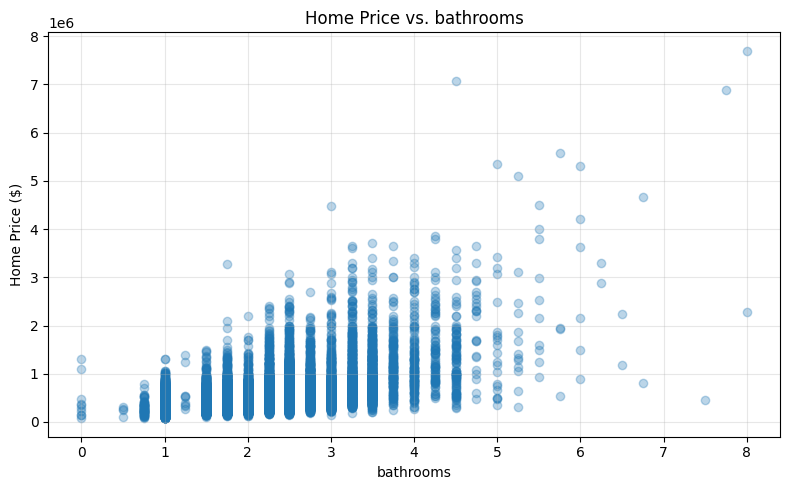

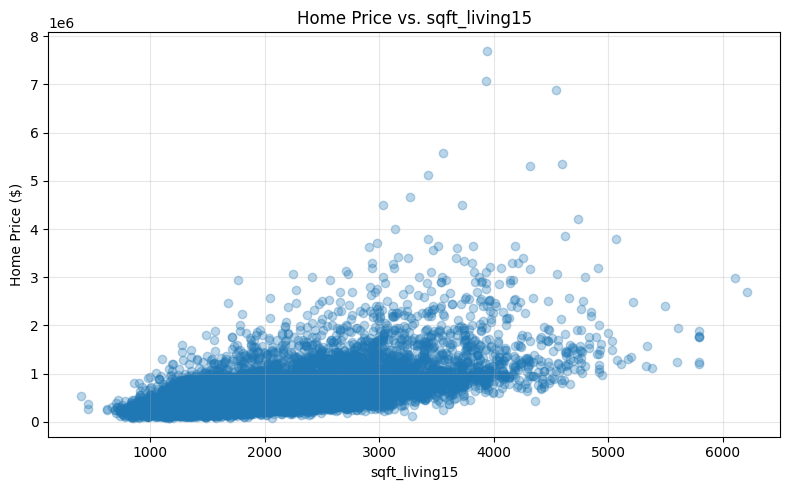

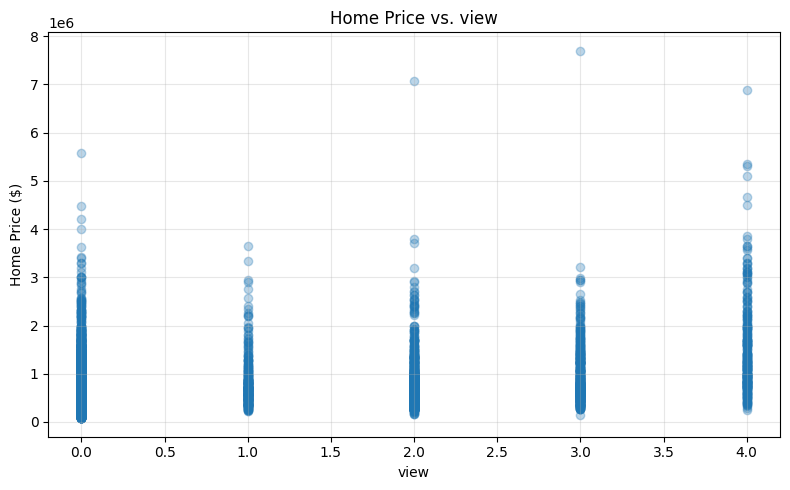

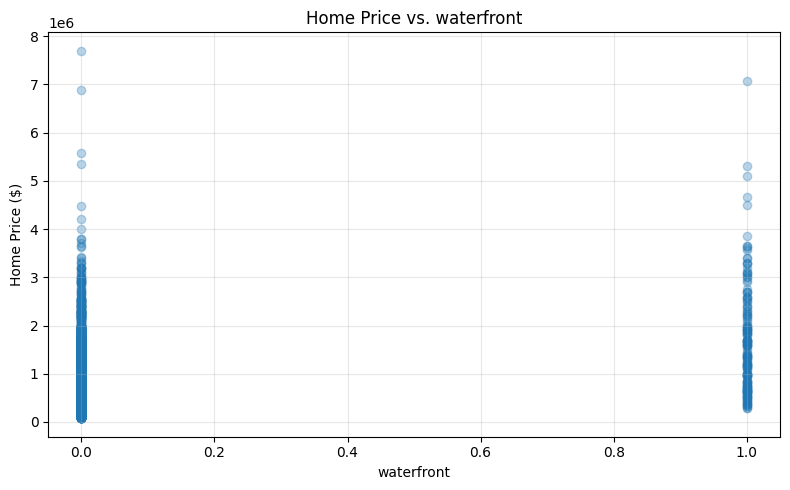

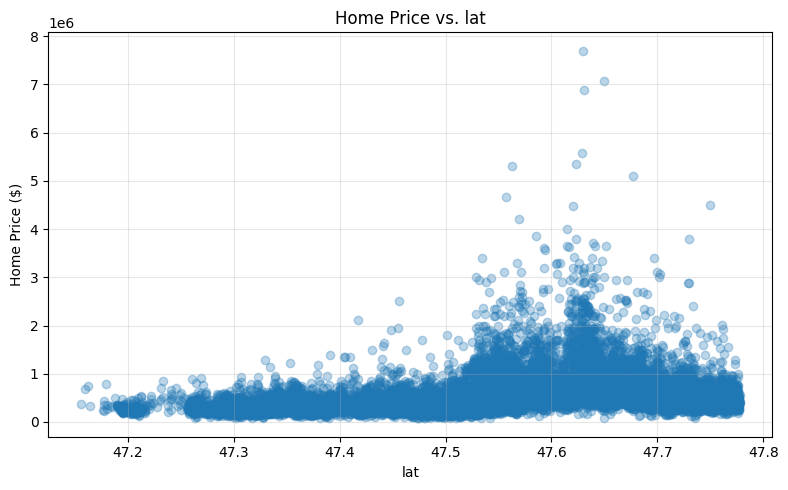

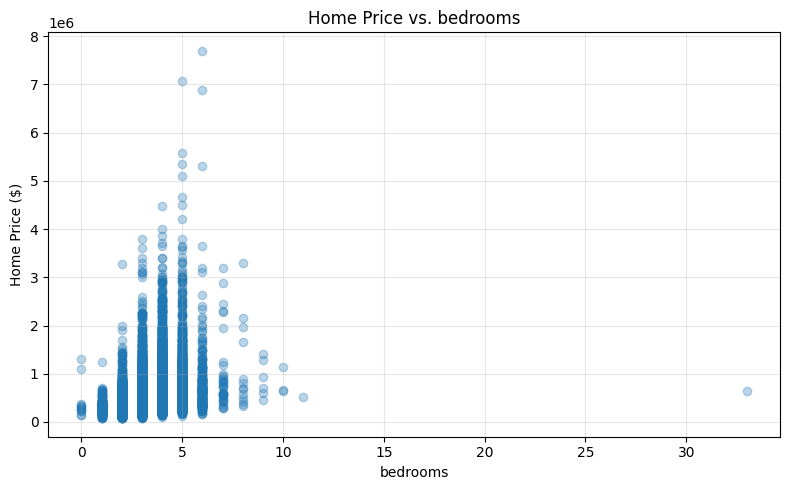


Pearson Correlation Results:
        Variable  Pearson_r  Pearson_p
0    sqft_living   0.702035        0.0
1          grade   0.667434        0.0
3  sqft_living15   0.585378        0.0
2      bathrooms   0.525136        0.0
4           view   0.397294        0.0
7       bedrooms   0.308377        0.0
6            lat   0.307003        0.0
5     waterfront   0.266370        0.0

Spearman Correlation Results:
        Variable  Spearman_rho    Spearman_p
1          grade      0.658216  0.000000e+00
0    sqft_living      0.644190  0.000000e+00
3  sqft_living15      0.572289  0.000000e+00
2      bathrooms      0.497159  0.000000e+00
6            lat      0.456410  0.000000e+00
7       bedrooms      0.344707  0.000000e+00
4           view      0.293931  0.000000e+00
5     waterfront      0.115089  1.254514e-64

Mutual Information Results:
        Variable  Mutual_Information
0    sqft_living            0.351472
1          grade            0.345514
6            lat            0.341699
3  sqf

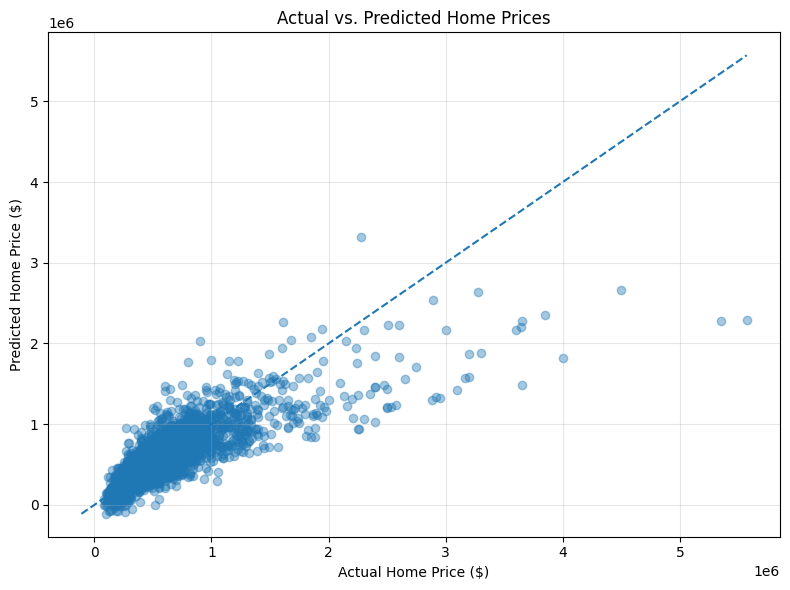

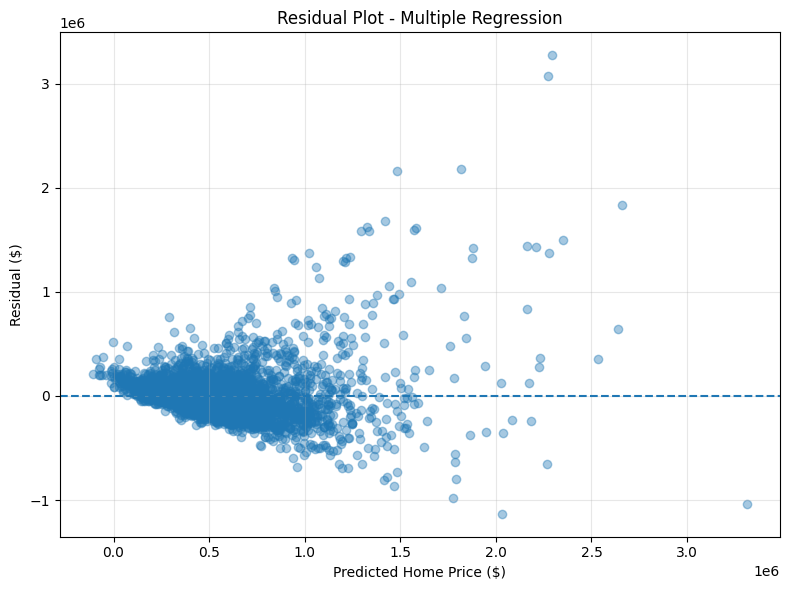


Multiple Regression Coefficients:
        Variable    Coefficient
6            lat  669388.708820
5     waterfront  581838.068668
1          grade   75002.786823
4           view   70146.086901
0    sqft_living     196.323545
3  sqft_living15       5.613053
2      bathrooms  -11059.311346
7       bedrooms  -22719.133558

FINAL SUMMARY

Simple Regression:
R² = 0.49285258522139186
Adjusted R² = 0.4928291181252473
Test R² = 0.49406904159708276
RMSE = 276559.17797157535

Multiple Regression:
R² = 0.6564471286257818
Adjusted R² = 0.6563199103805034
Test R² = 0.6606741137251626
RMSE = 226490.99732809234


In [ ]:
# ============================================================
# Assignment 13 - Multiple Regression Analysis
# Housing Price Dataset
# ============================================================

import zipfile
with zipfile.ZipFile('/content/Housing.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')
print("Housing.csv extracted successfully!")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

import statsmodels.api as sm

from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor


# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv("Housing.csv")

print("Dataset shape:")
print(df.shape)

print("\nFirst five rows:")
print(df.head())

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 2. SELECT RESPONSE AND CANDIDATE PREDICTORS
# ============================================================

target = 'price'

predictors = [
    'sqft_living',
    'grade',
    'bathrooms',
    'sqft_living15',
    'view',
    'waterfront',
    'lat',
    'bedrooms'
]

X = df[predictors].copy()
y = df[target].copy()


# ============================================================
# 3. BASIC DESCRIPTIVE STATISTICS
# ============================================================

print("\nDescriptive Statistics:")
print(df[predictors + [target]].describe())


# ============================================================
# 4. VISUALIZATION
# ============================================================

for variable in predictors:
    plt.figure(figsize=(8, 5))

    plt.scatter(
        df[variable],
        df[target],
        alpha=0.3
    )

    plt.xlabel(variable)
    plt.ylabel("Home Price ($)")
    plt.title(f"Home Price vs. {variable}")

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# 5. PEARSON CORRELATION
# ============================================================

pearson_results = []

for variable in predictors:
    r, p_value = stats.pearsonr(
        df[variable],
        df[target]
    )

    pearson_results.append({
        'Variable': variable,
        'Pearson_r': r,
        'Pearson_p': p_value
    })

pearson_table = pd.DataFrame(pearson_results)

pearson_table = pearson_table.sort_values(
    'Pearson_r',
    ascending=False
)

print("\nPearson Correlation Results:")
print(pearson_table)


# ============================================================
# 6. SPEARMAN CORRELATION
# ============================================================

spearman_results = []

for variable in predictors:
    rho, p_value = stats.spearmanr(
        df[variable],
        df[target]
    )

    spearman_results.append({
        'Variable': variable,
        'Spearman_rho': rho,
        'Spearman_p': p_value
    })

spearman_table = pd.DataFrame(spearman_results)

spearman_table = spearman_table.sort_values(
    'Spearman_rho',
    ascending=False
)

print("\nSpearman Correlation Results:")
print(spearman_table)


# ============================================================
# 7. MUTUAL INFORMATION
# ============================================================

mi_values = mutual_info_regression(
    X,
    y,
    random_state=42
)

mi_table = pd.DataFrame({
    'Variable': predictors,
    'Mutual_Information': mi_values
})

mi_table = mi_table.sort_values(
    'Mutual_Information',
    ascending=False
)

print("\nMutual Information Results:")
print(mi_table)


# ============================================================
# 8. MULTIPLE LINEAR REGRESSION USING STATSMODELS
# ============================================================

X_ols = sm.add_constant(X)

multi_model = sm.OLS(
    y,
    X_ols
).fit()

print("\nMultiple Regression Summary:")
print(multi_model.summary())


# ============================================================
# 9. EXTRACT KEY MULTIPLE REGRESSION RESULTS
# ============================================================

print("\nMultiple Regression Key Results:")

print("R-squared:")
print(multi_model.rsquared)

print("\nAdjusted R-squared:")
print(multi_model.rsquared_adj)

print("\nF-statistic:")
print(multi_model.fvalue)

print("\nOverall model p-value:")
print(multi_model.f_pvalue)

print("\nRegression coefficients:")
print(multi_model.params)

print("\nPredictor p-values:")
print(multi_model.pvalues)


# ============================================================
# 10. VARIANCE INFLATION FACTOR (VIF)
# ============================================================

X_vif = sm.add_constant(X)

vif_table = pd.DataFrame()

vif_table['Variable'] = X_vif.columns

vif_table['VIF'] = [
    variance_inflation_factor(
        X_vif.values,
        i
    )
    for i in range(X_vif.shape[1])
]

print("\nVariance Inflation Factors:")
print(vif_table)


# ============================================================
# 11. SIMPLE REGRESSION BASELINE
#     sqft_living only
# ============================================================

X_simple = df[['sqft_living']]

X_simple_ols = sm.add_constant(X_simple)

simple_model_ols = sm.OLS(
    y,
    X_simple_ols
).fit()

print("\nSimple Regression Summary:")
print(simple_model_ols.summary())


# ============================================================
# 12. TRAIN / TEST SPLIT
# ============================================================

train_index, test_index = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42
)


# ============================================================
# 13. SIMPLE MODEL - TRAIN / TEST PERFORMANCE
# ============================================================

simple_model = LinearRegression()

simple_model.fit(
    X_simple.loc[train_index],
    y.loc[train_index]
)

simple_predictions = simple_model.predict(
    X_simple.loc[test_index]
)

simple_test_r2 = r2_score(
    y.loc[test_index],
    simple_predictions
)

simple_rmse = np.sqrt(
    mean_squared_error(
        y.loc[test_index],
        simple_predictions
    )
)

print("\nSimple Model Test Performance:")
print("Test R-squared:", simple_test_r2)
print("RMSE:", simple_rmse)


# ============================================================
# 14. MULTIPLE MODEL - TRAIN / TEST PERFORMANCE
# ============================================================

multiple_model = LinearRegression()

multiple_model.fit(
    X.loc[train_index],
    y.loc[train_index]
)

multiple_predictions = multiple_model.predict(
    X.loc[test_index]
)

multiple_test_r2 = r2_score(
    y.loc[test_index],
    multiple_predictions
)

multiple_rmse = np.sqrt(
    mean_squared_error(
        y.loc[test_index],
        multiple_predictions
    )
)

print("\nMultiple Model Test Performance:")
print("Test R-squared:", multiple_test_r2)
print("RMSE:", multiple_rmse)


# ============================================================
# 15. SIMPLE VS MULTIPLE MODEL COMPARISON TABLE
# ============================================================

comparison_table = pd.DataFrame({
    'Metric': [
        'R-squared',
        'Adjusted R-squared',
        'Test R-squared',
        'RMSE'
    ],

    'Simple Regression': [
        simple_model_ols.rsquared,
        simple_model_ols.rsquared_adj,
        simple_test_r2,
        simple_rmse
    ],

    'Multiple Regression': [
        multi_model.rsquared,
        multi_model.rsquared_adj,
        multiple_test_r2,
        multiple_rmse
    ]
})

print("\nModel Comparison:")
print(comparison_table)


# ============================================================
# 16. COMBINED PREDICTOR RESULTS TABLE
# ============================================================

combined_table = pearson_table.merge(
    spearman_table,
    on='Variable'
)

combined_table = combined_table.merge(
    mi_table,
    on='Variable'
)

pvalue_table = pd.DataFrame({
    'Variable': predictors,
    'Regression_p_value': [
        multi_model.pvalues[var]
        for var in predictors
    ]
})

combined_table = combined_table.merge(
    pvalue_table,
    on='Variable'
)

vif_predictors = vif_table[
    vif_table['Variable'] != 'const'
].copy()

combined_table = combined_table.merge(
    vif_predictors,
    on='Variable'
)

print("\nCombined Predictor Evaluation Table:")
print(combined_table)


# ============================================================
# 17. PREDICTED VS ACTUAL PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y.loc[test_index],
    multiple_predictions,
    alpha=0.4
)

minimum = min(
    y.loc[test_index].min(),
    multiple_predictions.min()
)

maximum = max(
    y.loc[test_index].max(),
    multiple_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel("Actual Home Price ($)")
plt.ylabel("Predicted Home Price ($)")
plt.title("Actual vs. Predicted Home Prices")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 18. RESIDUAL PLOT FOR MULTIPLE REGRESSION
# ============================================================

multiple_residuals = (
    y.loc[test_index]
    - multiple_predictions
)

plt.figure(figsize=(8, 6))

plt.scatter(
    multiple_predictions,
    multiple_residuals,
    alpha=0.4
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel("Predicted Home Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residual Plot - Multiple Regression")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 19. OPTIONAL: SORT PREDICTORS BY IMPORTANCE FROM COEFFICIENTS
# ============================================================

coefficient_table = pd.DataFrame({
    'Variable': predictors,
    'Coefficient': multiple_model.coef_
})

coefficient_table = coefficient_table.sort_values(
    'Coefficient',
    ascending=False
)

print("\nMultiple Regression Coefficients:")
print(coefficient_table)


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print("\nFINAL SUMMARY")

print("\nSimple Regression:")
print("R² =", simple_model_ols.rsquared)
print("Adjusted R² =", simple_model_ols.rsquared_adj)
print("Test R² =", simple_test_r2)
print("RMSE =", simple_rmse)

print("\nMultiple Regression:")
print("R² =", multi_model.rsquared)
print("Adjusted R² =", multi_model.rsquared_adj)
print("Test R² =", multiple_test_r2)
print("RMSE =", multiple_rmse)